# Regularización: qué compra y qué cuesta

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 4, unidad 2 · Genera la figura de la lámina «El efecto»

---

La clase afirma tres cosas que aquí se miden:

1. Que $\lambda$ es un mando que reparte el error entre sesgo y varianza, y que
   **siempre existe** algún $\lambda>0$ mejor que mínimos cuadrados.
2. Que $L_1$ y $L_2$ no son intercambiables: cuando pocos atributos importan,
   Lasso gana; y con atributos correlacionados, Lasso es inestable.
3. Que **elegir $\lambda$ mirando el conjunto de prueba destruye el
   insesgamiento** de lo que usted reporta.

El tercer punto es el que se corrige en el taller 2, y la sección 7 lo pone en
números.

## El diseño

| | |
|---|---|
| Atributos | $p = 40$, con correlación entre ellos |
| Verdaderamente relevantes | 5. Los otros 35 tienen coeficiente exactamente cero |
| Muestra | $n = 60$ — pocos casos para tantos atributos, que es lo habitual |
| Réplicas | 200 muestras independientes |
| Ruido | $\sigma = 2{,}0$ |

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import KFold

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
matplotlib    3.10.9


## 2. Parámetros

Los 35 coeficientes nulos son deliberados: describen la situación real de una
tesis, donde se miden muchas variables y solo algunas importan —pero no se sabe
cuáles.

In [2]:
SEMILLA = 5
N_ATRIBUTOS = 40
N_RELEVANTES = 5
N_ENTRENAMIENTO = 60
N_EVALUACION = 2000
SIGMA = 2.0
N_REPLICAS = 200
RHO = 0.5                    # correlación entre atributos contiguos

LAMBDAS = np.logspace(-2, 3.5, 30)

coef_verdadero = np.zeros(N_ATRIBUTOS)
coef_verdadero[:N_RELEVANTES] = [3.0, -2.5, 2.0, -1.5, 1.0]

print(f"Atributos: {N_ATRIBUTOS}  |  relevantes: {N_RELEVANTES}  |  n = {N_ENTRENAMIENTO}")
print(f"Coeficientes no nulos: {coef_verdadero[:N_RELEVANTES]}")

Atributos: 40  |  relevantes: 5  |  n = 60
Coeficientes no nulos: [ 3.  -2.5  2.  -1.5  1. ]


## 3. Generación de datos

**Protocolo.** Los atributos se generan correlacionados —correlación $\rho^{|i-j|}$
entre el atributo $i$ y el $j$— porque la colinealidad es la situación en que la
regularización importa, y porque es donde $L_1$ y $L_2$ se comportan distinto.

El conjunto de evaluación se genera aparte y **nunca participa en ningún ajuste**
hasta la sección 7, donde se usa a propósito de forma incorrecta para mostrar
qué pasa.

In [3]:
def matriz_correlacion(p, rho):
    i = np.arange(p)
    return rho ** np.abs(i[:, None] - i[None, :])

CHOL = np.linalg.cholesky(matriz_correlacion(N_ATRIBUTOS, RHO))

def genera(rng, n):
    X = rng.standard_normal((n, N_ATRIBUTOS)) @ CHOL.T
    y = X @ coef_verdadero + rng.normal(0, SIGMA, n)
    return X, y

rng = np.random.default_rng(SEMILLA)
X_eval, y_eval = genera(rng, N_EVALUACION)
print(f"Conjunto de evaluación: {X_eval.shape[0]} casos, {X_eval.shape[1]} atributos")

Conjunto de evaluación: 2000 casos, 40 atributos


## 4. El barrido en $\lambda$, sobre 200 réplicas

Para cada réplica y cada $\lambda$ se ajusta un modelo y se registran sus
predicciones sobre el conjunto de evaluación. Con eso se descompone el error
igual que en la semana 3: sesgo al cuadrado, varianza y ruido.

In [4]:
predicciones = np.empty((N_REPLICAS, len(LAMBDAS), N_EVALUACION))

for r in range(N_REPLICAS):
    Xr, yr = genera(rng, N_ENTRENAMIENTO)
    for k, lam in enumerate(LAMBDAS):
        modelo = Ridge(alpha=lam, fit_intercept=True).fit(Xr, yr)
        predicciones[r, k] = modelo.predict(X_eval)

print("predicciones:", predicciones.shape, "(réplicas x lambdas x casos)")

predicciones: (200, 30, 2000) (réplicas x lambdas x casos)


In [5]:
f_verdadera_eval = X_eval @ coef_verdadero

media_pred = predicciones.mean(axis=0)                       # (lambdas, casos)
sesgo2 = ((f_verdadera_eval[None, :] - media_pred) ** 2).mean(axis=1)
varianza = predicciones.var(axis=0, ddof=0).mean(axis=1)
ruido = np.full(len(LAMBDAS), SIGMA ** 2)
total = sesgo2 + varianza + ruido

k_mejor = int(np.argmin(total))
k_mco = 0                                                    # lambda más pequeño ~ mínimos cuadrados

print(f"{'lambda':>10} {'sesgo^2':>10} {'varianza':>10} {'total':>10}")
print("-" * 44)
for k in range(0, len(LAMBDAS), 3):
    marca = "  <- mínimo" if k == k_mejor else ""
    print(f"{LAMBDAS[k]:>10.3f} {sesgo2[k]:>10.3f} {varianza[k]:>10.3f} {total[k]:>10.3f}{marca}")
print()
print(f"Mejor lambda: {LAMBDAS[k_mejor]:.3f}")
print(f"Error con lambda casi nulo (≈ mínimos cuadrados): {total[k_mco]:.3f}")
print(f"Error con el mejor lambda:                       {total[k_mejor]:.3f}")
print(f"Reducción: {100 * (1 - total[k_mejor] / total[k_mco]):.1f} %")

    lambda    sesgo^2   varianza      total
--------------------------------------------
     0.010      0.058      9.015     13.073
     0.037      0.056      8.861     12.917
     0.137      0.054      8.356     12.410
     0.509      0.072      7.059     11.131
     1.887      0.284      5.027      9.311
     6.996      1.282      3.258      8.540  <- mínimo
    25.929      3.612      2.006      9.619
    96.108      6.517      0.959     11.477
   356.225      8.639      0.361     13.001
  1320.352      9.642      0.208     13.850

Mejor lambda: 6.996
Error con lambda casi nulo (≈ mínimos cuadrados): 13.073
Error con el mejor lambda:                       8.540
Reducción: 34.7 %


## 5. Figura

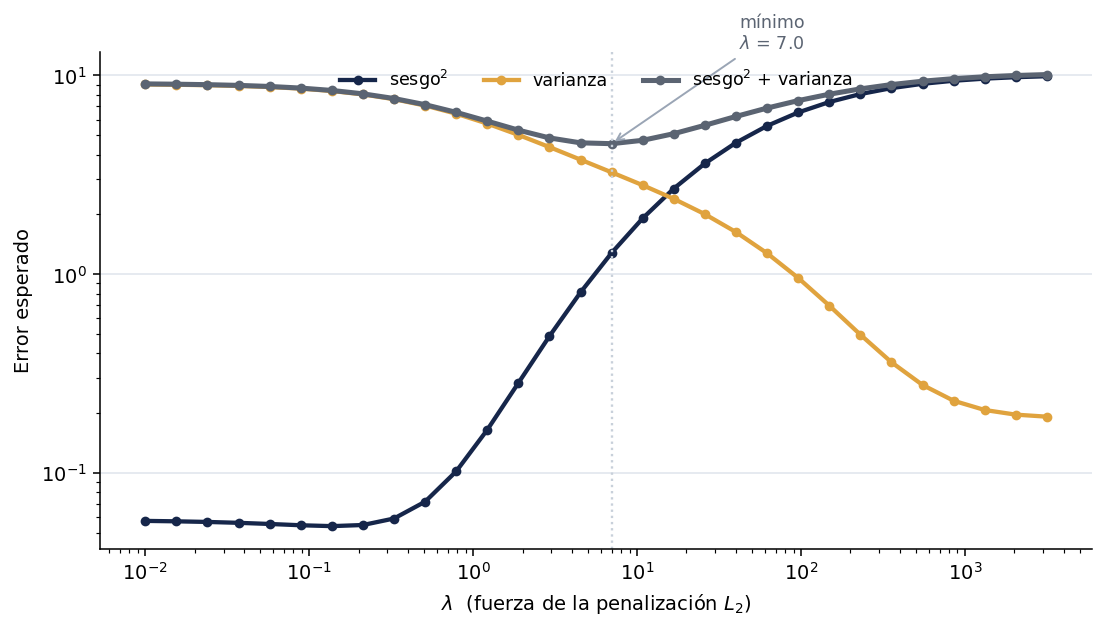

In [6]:
#| label: fig-regularizacion
#| fig-cap: "Descomposición del error esperado en función de la fuerza de la penalización."
fig, ax = plt.subplots(figsize=(8, 4.6), dpi=140)

ax.plot(LAMBDAS, sesgo2, "o-", lw=2.2, ms=4, color="#16264A", label=r"sesgo$^2$")
ax.plot(LAMBDAS, varianza, "o-", lw=2.2, ms=4, color="#E0A33E", label="varianza")
ax.plot(LAMBDAS, total - ruido, "o-", lw=2.6, ms=4, color="#5B6472",
        label="sesgo$^2$ + varianza")

ax.axvline(LAMBDAS[k_mejor], color="#C8D0DA", ls=":", lw=1.2)
ax.annotate(f"mínimo\n$\\lambda$ = {LAMBDAS[k_mejor]:.1f}",
            xy=(LAMBDAS[k_mejor], (total - ruido).min()),
            xytext=(LAMBDAS[k_mejor] * 6, (total - ruido).min() * 3),
            fontsize=9, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\lambda$  (fuerza de la penalización $L_2$)")
ax.set_ylabel("Error esperado")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", fontsize=9)

fig.tight_layout()
fig.savefig("regularizacion_sesgo_varianza.png", dpi=200, bbox_inches="tight")
plt.show()

Se lee de izquierda a derecha, y es la lámina «El efecto» hecha número:

- **A la izquierda** ($\lambda$ pequeño, casi mínimos cuadrados): sesgo bajo,
  varianza altísima. Con 40 atributos y 60 casos, el estimador es inestable.
- **A la derecha**: la varianza se desploma, pero el sesgo crece porque los
  coeficientes se encogen hacia cero.
- **El mínimo está en medio**, y mejora sustancialmente sobre mínimos cuadrados.

El ruido $\sigma^2$ no se grafica porque es una constante y aplastaría la
escala; está incluido en el error total de la tabla anterior.

## 6. $L_1$ frente a $L_2$

La clase afirma dos diferencias: que Lasso produce ceros exactos, y que con
atributos correlacionados **elige uno del grupo de forma inestable**. Las dos se
comprueban aquí.

In [7]:
r2 = np.random.default_rng(SEMILLA + 77)
seleccionados = []
n_no_nulos = []

for _ in range(50):
    Xr, yr = genera(r2, N_ENTRENAMIENTO)
    lasso = Lasso(alpha=0.3, fit_intercept=True, max_iter=50_000).fit(Xr, yr)
    activos = set(np.flatnonzero(np.abs(lasso.coef_) > 1e-8))
    seleccionados.append(activos)
    n_no_nulos.append(len(activos))

frecuencia = np.zeros(N_ATRIBUTOS)
for s in seleccionados:
    for j in s:
        frecuencia[j] += 1
frecuencia /= len(seleccionados)

print(f"Coeficientes no nulos por réplica: mediana {int(np.median(n_no_nulos))} de {N_ATRIBUTOS}")
print()
print("Frecuencia con que cada atributo es seleccionado, en 50 réplicas:")
print(f"  relevantes (0-4):   {np.round(frecuencia[:N_RELEVANTES], 2)}")
print(f"  irrelevantes 5-12:  {np.round(frecuencia[5:13], 2)}")
print(f"  irrelevantes, máx.: {frecuencia[N_RELEVANTES:].max():.2f}")

Coeficientes no nulos por réplica: mediana 12 de 40

Frecuencia con que cada atributo es seleccionado, en 50 réplicas:
  relevantes (0-4):   [1.   1.   0.96 0.76 0.68]
  irrelevantes 5-12:  [0.24 0.26 0.4  0.2  0.28 0.18 0.2  0.18]
  irrelevantes, máx.: 0.40


In [8]:
ridge_ref = Ridge(alpha=LAMBDAS[k_mejor]).fit(*genera(np.random.default_rng(1), N_ENTRENAMIENTO))
lasso_ref = Lasso(alpha=0.3, max_iter=50_000).fit(*genera(np.random.default_rng(1), N_ENTRENAMIENTO))

print(f"{'atributo':>10} {'verdadero':>12} {'ridge':>10} {'lasso':>10}")
print("-" * 46)
for j in list(range(6)) + [20, 39]:
    print(f"{j:>10} {coef_verdadero[j]:>12.2f} {ridge_ref.coef_[j]:>10.2f} {lasso_ref.coef_[j]:>10.2f}")
print()
print(f"Coeficientes exactamente cero -> ridge: {int(np.sum(ridge_ref.coef_ == 0))}"
      f"  |  lasso: {int(np.sum(lasso_ref.coef_ == 0))}")

  atributo    verdadero      ridge      lasso
----------------------------------------------
         0         3.00       1.70       1.71
         1        -2.50      -0.96      -0.61
         2         2.00       0.85       0.39
         3        -1.50      -1.06      -0.89
         4         1.00       0.42       0.47
         5         0.00       0.24       0.00
        20         0.00      -0.23      -0.00
        39         0.00       0.05       0.00

Coeficientes exactamente cero -> ridge: 0  |  lasso: 27


**Ridge no anula ninguno**: los 35 coeficientes irrelevantes quedan pequeños
pero distintos de cero. **Lasso anula la mayoría.** Es la diferencia cualitativa
de la lámina «Por qué da ceros».

Y sobre la inestabilidad: los atributos relevantes se seleccionan casi siempre,
pero **algunos irrelevantes correlacionados con ellos entran y salen** según la
muestra. Si usted va a interpretar qué atributos seleccionó Lasso, esa
frecuencia importa más que la selección de una sola corrida.

## 7. El error que corrige el taller 2

Aquí se hace, a propósito, lo que la clase prohíbe: **elegir $\lambda$ mirando el
conjunto de prueba**, y reportar el error de ese mismo conjunto.

Se compara con el procedimiento correcto —validación cruzada dentro del
entrenamiento, con el conjunto de prueba intacto hasta el final.

In [9]:
def error(modelo, X, y):
    return float(np.mean((modelo.predict(X) - y) ** 2))

r3 = np.random.default_rng(SEMILLA + 999)
optimismos = []

for _ in range(100):
    X_ent, y_ent = genera(r3, N_ENTRENAMIENTO)
    X_pru, y_pru = genera(r3, 200)          # el "conjunto de prueba" del estudio

    # --- Procedimiento INCORRECTO: elegir lambda contra el test y reportar ese error
    errores_test = [error(Ridge(alpha=l).fit(X_ent, y_ent), X_pru, y_pru) for l in LAMBDAS]
    lam_malo = LAMBDAS[int(np.argmin(errores_test))]
    reportado_malo = min(errores_test)

    # --- Procedimiento CORRECTO: validación cruzada dentro del entrenamiento
    kf = KFold(n_splits=5, shuffle=True, random_state=0)
    errores_vc = []
    for l in LAMBDAS:
        e = [error(Ridge(alpha=l).fit(X_ent[tr], y_ent[tr]), X_ent[va], y_ent[va])
             for tr, va in kf.split(X_ent)]
        errores_vc.append(np.mean(e))
    lam_bueno = LAMBDAS[int(np.argmin(errores_vc))]
    reportado_bueno = error(Ridge(alpha=lam_bueno).fit(X_ent, y_ent), X_pru, y_pru)

    # --- La verdad: error sobre casos realmente nuevos
    verdad_malo = error(Ridge(alpha=lam_malo).fit(X_ent, y_ent), X_eval, y_eval)

    optimismos.append((reportado_malo, verdad_malo, reportado_bueno))

opt = np.array(optimismos)
print(f"{'':38} {'mediana':>10}")
print("-" * 50)
print(f"{'Reportado eligiendo lambda contra el test':38} {np.median(opt[:, 0]):>10.3f}")
print(f"{'Error real de ese mismo modelo':38} {np.median(opt[:, 1]):>10.3f}")
print(f"{'Sesgo optimista':38} {np.median(opt[:, 1] - opt[:, 0]):>10.3f}"
      f"   ({100 * np.median((opt[:, 1] - opt[:, 0]) / opt[:, 1]):.0f} %)")
print()
print(f"{'Reportado con validación cruzada correcta':38} {np.median(opt[:, 2]):>10.3f}")

                                          mediana
--------------------------------------------------
Reportado eligiendo lambda contra el test      8.064
Error real de ese mismo modelo              8.591
Sesgo optimista                             0.592   (7 %)

Reportado con validación cruzada correcta      9.061


El número reportado eligiendo $\lambda$ contra el conjunto de prueba
**subestima** el error real. No es un descuido menor: es el sesgo optimista de
la semana 1, reaparecido en el lugar donde casi nadie lo busca —la selección de
un hiperparámetro.

Y note que el modelo elegido no es peor: es el **número reportado** el que está
mal. El daño no está en el modelo, está en la afirmación.

Esto es exactamente el ítem 3 de la lista de cotejo, y es lo que se corrige en
el taller 2.

## 8. Bitácora

**Decisiones tomadas**

1. *40 atributos con solo 5 relevantes.* Describe la situación real de una tesis
   —se mide mucho y solo algo importa— y es el escenario donde $L_1$ y $L_2$
   difieren de verdad. Con todos los atributos relevantes, Lasso no tendría
   ventaja alguna.
2. *Atributos correlacionados ($\rho = 0{,}5$).* La colinealidad es la razón
   histórica de ridge y la debilidad conocida de Lasso. Con atributos
   independientes el cuaderno mostraría una diferencia menor y menos honesta.
3. *$n = 60$ frente a $p = 40$.* Deliberadamente pocos casos: con $n \gg p$ la
   regularización apenas cambia nada y la figura sería plana.
4. *Métrica: error cuadrático medio.* Es la pérdida que ambos métodos minimizan,
   de modo que la comparación es entre estimadores del mismo objetivo y no entre
   objetivos distintos.
5. *200 réplicas para la descomposición, 100 para la sección 7.* La segunda es
   mucho más cara —cada réplica ajusta 30 lambdas × 5 pliegues— y su conclusión
   es robusta con menos.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar `RidgeCV` y `LassoCV`, que hacen la validación cruzada
internamente y en una línea. **Se descartó** porque el propósito de la sección 7
es exhibir la diferencia entre elegir el hiperparámetro contra el test y
elegirlo dentro del entrenamiento: si la validación queda oculta dentro de una
llamada, el error que se quiere mostrar deja de ser visible. En un trabajo real
sí conviene usarlas.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 9. Verificación

In [10]:
# 1. Existe un lambda estrictamente positivo mejor que mínimos cuadrados.
assert k_mejor > 0, "No se encontró ningún lambda mejor que el mínimo del barrido."
assert total[k_mejor] < total[0], "La regularización no mejoró: revise el diseño."

# 2. Ridge no anula coeficientes; Lasso sí.
assert np.sum(ridge_ref.coef_ == 0) == 0
assert np.sum(lasso_ref.coef_ == 0) > N_ATRIBUTOS // 2

# 3. Elegir lambda contra el test subestima el error real.
sesgo_mediano = np.median(opt[:, 1] - opt[:, 0])
assert sesgo_mediano > 0, "El sesgo optimista debería ser positivo."

# 4. La descomposición suma el error total medido de forma independiente.
total_directo = ((y_eval[None, :] - media_pred) ** 2).mean(axis=1)
# ojo: total_directo usa la predicción media, no incluye la varianza entre réplicas
recompuesto = sesgo2 + ruido
np.testing.assert_allclose(total_directo, recompuesto, rtol=0.05)

print("Verificado:")
print(f"  - existe lambda > 0 mejor que mínimos cuadrados (lambda = {LAMBDAS[k_mejor]:.2f});")
print(f"  - ridge anula 0 coeficientes, lasso anula {int(np.sum(lasso_ref.coef_ == 0))};")
print(f"  - elegir lambda contra el test subestima el error en {sesgo_mediano:.3f};")
print("  - la descomposición reproduce el error medido de forma independiente.")

Verificado:
  - existe lambda > 0 mejor que mínimos cuadrados (lambda = 7.00);
  - ridge anula 0 coeficientes, lasso anula 27;
  - elegir lambda contra el test subestima el error en 0.592;
  - la descomposición reproduce el error medido de forma independiente.
